# The number changed after a save: which writers give a float64 back bit for bit

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phoebefu6/phoebe-the-builder/blob/main/data-engineering-pro/float-roundtrip/demo.ipynb)
[![Binder](https://mybinder.org/badge_logo.svg)](https://mybinder.org/v2/gh/phoebefu6/phoebe-the-builder/main?labpath=data-engineering-pro/float-roundtrip/demo.ipynb)

A float64 has 17 significant digits. Many ways of saving it write fewer, and some readers misread a file that was
written correctly. Nothing errors: the value comes back a few bits different, and every join or dedupe key on that
column stops matching. This notebook sends four groups of fictional values through 15 writers and compares what
comes back bit for bit.

1. The engine
2. Exact, changed, lost
3. Why a test fixture misses it
4. The total does not move; the keys do
5. Edge values
6. pandas: the file is exact, the reader is not
7. The chart
8. Try your own

## 1. The engine

Extracted from `explore.py` and `evidence.py` at build time. Seeded (`Generator(213)`), every value fictional, and
every number below matches `evidence.txt` exactly.

In [1]:
from __future__ import annotations

import csv
import io
import json
import math
import pickle
import sqlite3
import struct
from typing import Callable, Dict, List, Optional

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


class _E:  # evidence.py refers to the engine as E
    pass

SEED = 213


N = 2000


GROUPS = ["entered", "computed", "measured", "edge"]


EDGE = [0.0, -0.0, float("nan"), float("inf"), float("-inf"), 5e-324, 2.2250738585072014e-308,
        1.7976931348623157e308, 0.1 + 0.2, float(2**53 + 2), 1e16 + 2.0, 123456789.12345679]


def make_values(seed: int = SEED) -> Dict[str, List[float]]:
    g = np.random.default_rng(seed)
    entered = np.round(g.uniform(0.01, 50_000, N), 2)
    rate = np.round(g.uniform(0.5, 1.6, N), 6)
    computed = entered * rate / 3.0
    measured = g.uniform(1, 10, N) * 10.0 ** g.integers(-10, 10, N)
    return {"entered": [float(x) for x in entered], "computed": [float(x) for x in computed],
            "measured": [float(x) for x in measured], "edge": list(EDGE)}


def _each(fn: Callable[[float], float]) -> Callable[[List[float]], List[Optional[float]]]:
    def run(xs: List[float]) -> List[Optional[float]]:
        out: List[Optional[float]] = []
        for x in xs:
            try:
                out.append(fn(x))
            except (ValueError, OverflowError):
                out.append(None)
        return out
    return run


def _json(xs: List[float]) -> List[Optional[float]]:
    return json.loads(json.dumps(xs))


def _json_strict(xs: List[float]) -> List[Optional[float]]:
    out: List[Optional[float]] = []
    for x in xs:  # one document per value, as an API would send it; NaN/inf are not JSON
        try:
            out.append(json.loads(json.dumps({"v": x}, allow_nan=False))["v"])
        except ValueError:
            out.append(None)
    return out


def _csv_module(xs: List[float]) -> List[Optional[float]]:
    buf = io.StringIO()
    csv.writer(buf).writerows([[x] for x in xs])
    return [float(r[0]) for r in csv.reader(io.StringIO(buf.getvalue()))]


def _pandas(xs: List[float], precision: Optional[str] = None, fmt: Optional[str] = None) -> List[Optional[float]]:
    text = pd.DataFrame({"v": xs}).to_csv(index=False, float_format=fmt)
    v = pd.read_csv(io.StringIO(text), float_precision=precision)["v"]
    return [None if (isinstance(a, float) and math.isnan(a) and not math.isnan(b)) else float(a)
            for a, b in zip(v.tolist(), xs)]


def _sqlite(xs: List[float], as_text: bool) -> List[Optional[float]]:
    con = sqlite3.connect(":memory:")
    con.execute("CREATE TABLE t (i INTEGER, v REAL)")
    con.executemany("INSERT INTO t VALUES (?, ?)", list(enumerate(xs)))
    q = "SELECT CAST(v AS TEXT) FROM t ORDER BY i" if as_text else "SELECT v FROM t ORDER BY i"
    rows = [r[0] for r in con.execute(q)]
    con.close()
    return [None if r is None else float(r) for r in rows]


def _savetxt(xs: List[float]) -> List[Optional[float]]:
    buf = io.StringIO()
    np.savetxt(buf, np.array(xs))
    return [float(v) for v in np.loadtxt(io.StringIO(buf.getvalue()), ndmin=1)]


WRITERS: Dict[str, Callable[[List[float]], List[Optional[float]]]] = {
    "repr": _each(lambda x: float(repr(x))),
    "%.17g": _each(lambda x: float("%.17g" % x)),
    "pickle": lambda xs: pickle.loads(pickle.dumps(xs)),
    "np.savetxt": _savetxt,
    "sqlite REAL": lambda xs: _sqlite(xs, False),
    "json": _json,
    "json strict": _json_strict,
    "csv module": _csv_module,
    "pandas round_trip": lambda xs: _pandas(xs, precision="round_trip"),
    "pandas csv": lambda xs: _pandas(xs),
    "pandas legacy": lambda xs: _pandas(xs, precision="legacy"),
    "%.15g": _each(lambda x: float("%.15g" % x)),
    "sqlite TEXT": lambda xs: _sqlite(xs, True),
    "pandas %.6f": lambda xs: _pandas(xs, fmt="%.6f"),
    "float32": _each(lambda x: struct.unpack("f", struct.pack("f", x))[0]),
}


WHAT = {
    "repr": "Python repr / str: shortest string that reads back",
    "%.17g": "17 significant digits",
    "pickle": "binary",
    "np.savetxt": "NumPy default fmt %.18e",
    "sqlite REAL": "SQLite REAL column, read as a number",
    "json": "json.dumps / loads (writes NaN, Infinity - not JSON)",
    "json strict": "json.dumps(allow_nan=False), one document per value",
    "csv module": "csv.writer / float()",
    "pandas round_trip": "to_csv / read_csv(float_precision='round_trip')",
    "pandas csv": "to_csv / read_csv defaults (the file is exact; the reader is not)",
    "pandas legacy": "read_csv(float_precision='legacy')",
    "%.15g": "15 significant digits (DBL_DIG, what a spreadsheet shows)",
    "sqlite TEXT": "SQLite CAST(v AS TEXT), as a text export does",
    "pandas %.6f": "to_csv(float_format='%.6f')",
    "float32": "a FLOAT (4-byte) column",
}


def bits(x: float) -> int:
    """Ordered integer for a double: adjacent doubles differ by 1, so |a - b| is the ULP distance."""
    i = struct.unpack("<q", struct.pack("<d", x))[0]
    return i if i >= 0 else -(i & 0x7FFFFFFFFFFFFFFF)


def compare(xs: List[float], ys: List[Optional[float]]) -> Dict[str, float]:
    exact = changed = lost = 0
    max_ulp = 0
    for x, y in zip(xs, ys):
        if y is None or (math.isnan(y) and not math.isnan(x)):
            lost += 1
        elif math.isnan(x) and math.isnan(y):
            exact += 1
        elif struct.pack("<d", x) == struct.pack("<d", y):
            exact += 1
        else:
            changed += 1
            if math.isfinite(x) and math.isfinite(y):
                max_ulp = max(max_ulp, abs(bits(x) - bits(y)))
    return {"n": len(xs), "exact": exact, "changed": changed, "lost": lost, "max_ulp": max_ulp}


def run(values: Dict[str, List[float]]) -> Dict[str, Dict[str, Dict[str, float]]]:
    return {w: {g: compare(values[g], fn(values[g])) for g in GROUPS} for w, fn in WRITERS.items()}


def ledger(values: Dict[str, List[float]], writer: str) -> Dict[str, float]:
    """What the change does downstream on the computed column: total drift vs keys that stop matching."""
    xs = values["computed"]
    ys = WRITERS[writer](xs)
    kept = [y for y in ys if y is not None]
    before, after = math.fsum(xs), math.fsum(kept)
    orig = {struct.pack("<d", x) for x in xs}
    miss = sum(1 for y in ys if y is None or struct.pack("<d", y) not in orig)
    return {"total_before": before, "total_after": after, "drift": after - before,
            "join_miss": miss / len(xs), "dedupe_after": len(set(kept)), "dedupe_before": len(set(xs))}


def edge_detail(writer: str) -> List[str]:
    """What each edge value came back as, as text."""
    ys = WRITERS[writer](list(EDGE))
    return ["lost" if y is None else repr(y) for y in ys]


def study(seed: int = SEED) -> dict:
    v = make_values(seed)
    return {"writers": run(v), "ledger": {w: ledger(v, w) for w in WRITERS},
            "edge": {w: edge_detail(w) for w in WRITERS}}


def seeds(n: int = 30) -> dict:
    """Changed share of the computed column per writer, across n more worlds."""
    out: Dict[str, List[float]] = {w: [] for w in WRITERS}
    for s in range(1, n + 1):
        v = make_values(SEED + s)
        for w, fn in WRITERS.items():
            c = compare(v["computed"], fn(v["computed"]))
            out[w].append((c["changed"] + c["lost"]) / c["n"])
    return {"n": n, "range": {w: (min(r), max(r)) for w, r in out.items()}}


E = _E()
E.__dict__.update(globals())

def lines(r: dict, s: dict) -> List[str]:
    out: List[str] = []
    w = out.append
    wr = r["writers"]
    w(f"float-roundtrip evidence  ({E.N:,} fictional values per group, seeded Generator({E.SEED}); "
      f"{s['n']} more worlds for the computed column; bits compared, NaN read as NaN counts as exact)")
    w("")
    w("1. Exact / changed / lost per writer and value group")
    w(f"{'writer':<18}" + "".join(f"{g:>22}" for g in E.GROUPS) + "   max ULP off")
    for k in E.WRITERS:
        cells = "".join(f"{d['exact']:>8}/{d['changed']:>6}/{d['lost']:>4}   " for d in wr[k].values())
        w(f"{k:<18}{cells}{max(d['max_ulp'] for d in wr[k].values()):>12,}")
    clean = [k for k in E.WRITERS if all(d["changed"] + d["lost"] == 0 for d in wr[k].values())]
    w("max ULP off counts adjacent doubles between sent and received; across a flush to 0.0 (pandas %.6f, float32) "
      "it is astronomical and means the value was destroyed, not nudged")
    w(f"bit-exact on all four groups: {len(clean)} of {len(E.WRITERS)} ({', '.join(clean)})")
    w("")
    w("2. A fixture of typed amounts passes every writer except float32")
    passes = [k for k in E.WRITERS if wr[k]["entered"]["exact"] == E.N]
    w(f"entered (two decimals) exact for {len(passes)} of {len(E.WRITERS)} writers; "
      f"the same writers on the computed column: "
      + ", ".join(f"{k} {100 * (1 - wr[k]['computed']['exact'] / E.N):.1f}% changed"
                  for k in passes if wr[k]["computed"]["exact"] < E.N))
    w("")
    w("3. The total does not move; the keys do (computed column, after the round trip)")
    w(f"{'writer':<18}{'total drift':>14}{'join keys lost':>16}   30-world range")
    for k in E.WRITERS:
        lg = r["ledger"][k]
        lo, hi = s["range"][k]
        w(f"{k:<18}{lg['drift']:>14.2e}{100 * lg['join_miss']:>15.1f}%   {100 * lo:.1f}-{100 * hi:.1f}%")
    w(f"total before = {r['ledger']['repr']['total_before']:,.2f}; 'drift' is math.fsum(after) - math.fsum(before)")
    w("")
    w("4. Edge values: what came back")
    w("in:  " + " | ".join(repr(x) for x in E.EDGE))
    for k in E.WRITERS:
        got = r["edge"][k]
        diff = [f"{E.EDGE[i]!r} -> {g}" for i, g in enumerate(got) if g != repr(E.EDGE[i])]
        w(f"{k:<18}" + ("all exact" if not diff else "; ".join(diff)))
    w("")
    w("5. pandas: the file is exact, the default reader is not")
    for k in ("pandas round_trip", "pandas csv", "pandas legacy"):
        d = wr[k]["measured"]
        w(f"{k:<18} measured column: {d['changed']} of {E.N} changed, worst {d['max_ulp']:,} ULP")
    return out


def main() -> None:
    r = E.study()
    s = E.seeds()
    json.dump({"study": r, "seeds": s}, open("results.json", "w"), indent=1)
    text = "\n".join(lines(r, s)) + "\n"
    open("evidence.txt", "w").write(text)
    print(text)

In [2]:
r = study()
s = seeds()
out = lines(r, s)
section = lambda n: [l for l in "\n".join(out).split(f"\n{n}. ")[1].split("\n\n")[0].splitlines()]
print(out[0])

float-roundtrip evidence  (2,000 fictional values per group, seeded Generator(213); 30 more worlds for the computed column; bits compared, NaN read as NaN counts as exact)


## 2. Exact, changed, lost

Seven of 15 writers give every value back bit for bit: repr, %.17g, pickle, np.savetxt, json, the csv module and
pandas with `float_precision='round_trip'`. Writing 15 significant digits changes 1318 of 2000 computed values, and
SQLite's text cast does exactly the same thing.

In [3]:
print("\n".join(section(1)))

Exact / changed / lost per writer and value group
writer                           entered              computed              measured                  edge   max ULP off
repr                  2000/     0/   0       2000/     0/   0       2000/     0/   0         12/     0/   0              0
%.17g                 2000/     0/   0       2000/     0/   0       2000/     0/   0         12/     0/   0              0
pickle                2000/     0/   0       2000/     0/   0       2000/     0/   0         12/     0/   0              0
np.savetxt            2000/     0/   0       2000/     0/   0       2000/     0/   0         12/     0/   0              0
sqlite REAL           2000/     0/   0       2000/     0/   0       2000/     0/   0         10/     1/   1              0
json                  2000/     0/   0       2000/     0/   0       2000/     0/   0         12/     0/   0              0
json strict           2000/     0/   0       2000/     0/   0       2000/     0/   0       

## 3. Why a test fixture misses it

Typed amounts with two decimals have a short exact decimal form, so 14 of 15 writers give them back. A fixture of
typed amounts passes every writer except float32. The same writers fail on the amounts a pipeline actually holds:
after an FX rate and a split.

In [4]:
print("\n".join(section(2)))

A fixture of typed amounts passes every writer except float32
entered (two decimals) exact for 14 of 15 writers; the same writers on the computed column: pandas csv 14.3% changed, pandas legacy 25.9% changed, %.15g 65.9% changed, sqlite TEXT 65.9% changed, pandas %.6f 97.9% changed


## 4. The total does not move; the keys do

The ledger total over 2000 computed amounts is unchanged to the last bit after a 15-digit round trip, because the
rounding errors are far below a cent and cancel. A reconciliation on the total passes. Two-thirds of the values no
longer equal their source, so an exact join or a dedupe key on that column misses them.

In [5]:
print("\n".join(section(3)))

The total does not move; the keys do (computed column, after the round trip)
writer               total drift  join keys lost   30-world range
repr                    0.00e+00            0.0%   0.0-0.0%
%.17g                   0.00e+00            0.0%   0.0-0.0%
pickle                  0.00e+00            0.0%   0.0-0.0%
np.savetxt              0.00e+00            0.0%   0.0-0.0%
sqlite REAL             0.00e+00            0.0%   0.0-0.0%
json                    0.00e+00            0.0%   0.0-0.0%
json strict             0.00e+00            0.0%   0.0-0.0%
csv module              0.00e+00            0.0%   0.0-0.0%
pandas round_trip       0.00e+00            0.0%   0.0-0.0%
pandas csv              0.00e+00           14.3%   12.7-15.4%
pandas legacy           0.00e+00           25.9%   25.9-30.5%
%.15g                   0.00e+00           65.9%   65.9-69.4%
sqlite TEXT             0.00e+00           65.9%   65.9-69.4%
pandas %.6f             1.30e-05           97.9%   97.7-98.8%
float32

## 5. Edge values

SQLite stores NaN as NULL and -0.0 as 0.0, even in a REAL column. Strict JSON refuses NaN and infinity, which is
correct and still loses the value if the caller swallows the error. Fifteen digits turn the largest double into
infinity.

In [6]:
print("\n".join(section(4)))

Edge values: what came back
in:  0.0 | -0.0 | nan | inf | -inf | 5e-324 | 2.2250738585072014e-308 | 1.7976931348623157e+308 | 0.30000000000000004 | 9007199254740994.0 | 1.0000000000000002e+16 | 123456789.12345679
repr              all exact
%.17g             all exact
pickle            all exact
np.savetxt        all exact
sqlite REAL       -0.0 -> 0.0; nan -> lost
json              all exact
json strict       nan -> lost; inf -> lost; -inf -> lost
csv module        all exact
pandas round_trip all exact
pandas csv        0.30000000000000004 -> 0.3; 123456789.12345679 -> 123456789.1234568
pandas legacy     all exact
%.15g             2.2250738585072014e-308 -> 2.2250738585072e-308; 1.7976931348623157e+308 -> inf; 0.30000000000000004 -> 0.3; 9007199254740994.0 -> 9007199254740990.0; 1.0000000000000002e+16 -> 1e+16; 123456789.12345679 -> 123456789.123457
sqlite TEXT       -0.0 -> 0.0; nan -> lost; 2.2250738585072014e-308 -> 2.2250738585072e-308; 1.7976931348623157e+308 -> inf; 0.300000000

## 6. pandas: the file is exact, the reader is not

`to_csv` writes the shortest exact string. The default `read_csv` parser then misreads some of them, by up to
thousands of ULP on small values. `float_precision='round_trip'` reads every one back exactly.

In [7]:
print("\n".join(section(5)))

pandas: the file is exact, the default reader is not
pandas round_trip  measured column: 0 of 2000 changed, worst 0 ULP
pandas csv         measured column: 537 of 2000 changed, worst 5,506 ULP
pandas legacy      measured column: 605 of 2000 changed, worst 2 ULP


## 7. The chart

The two-panel figure is `roundtrip.png` (built by `make_chart.py`). This is the computed column on its own.

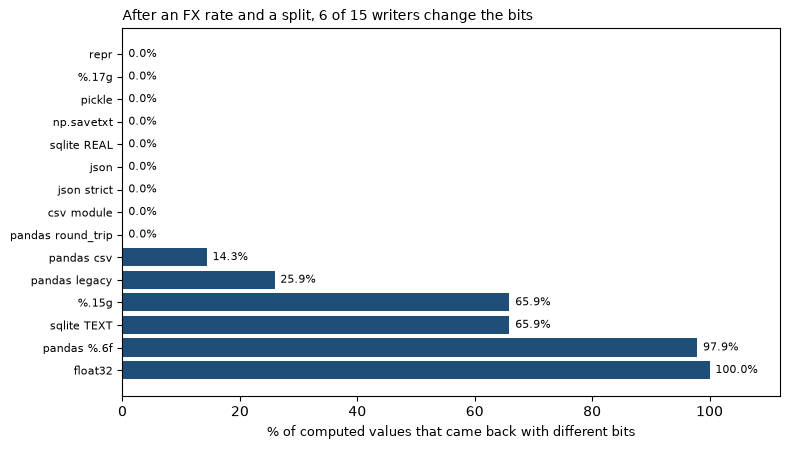

In [8]:
wr = r["writers"]
names = list(WRITERS)[::-1]
vals = [100 * (wr[k]["computed"]["changed"] + wr[k]["computed"]["lost"]) / N for k in names]
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(range(len(names)), vals, color=["#1f4e79" if v else "#a9c8e4" for v in vals])
ax.set_yticks(range(len(names)), names, fontsize=8)
for i, v in enumerate(vals):
    ax.text(v + 1, i, f"{v:.1f}%", va="center", fontsize=8)
ax.set_xlim(0, 112)
ax.set_xlabel("% of computed values that came back with different bits", fontsize=9)
ax.set_title("After an FX rate and a split, 6 of 15 writers change the bits", loc="left", fontsize=10)
plt.tight_layout()
plt.savefig("notebook_chart.png", dpi=120)
plt.show()

## Summary

- Write floats with repr, %.17g or a binary format. Fifteen significant digits is a display format, not a storage one.
- SQLite's `CAST(v AS TEXT)` is a 15-digit format; a REAL column also drops NaN and the sign of zero.
- pandas writes CSV exactly; read it with `float_precision='round_trip'`.
- Test with computed values, not typed ones: a two-decimal fixture passes every writer but float32.
- A reconciliation on the total passes while the join keys break. Check equality on the column, not the sum.

## 8. Try your own

In [9]:
# x = 1234.5678 * 0.731 / 3                     # any value you compute in a pipeline
# for name, fn in WRITERS.items():
#     y = fn([x])[0]
#     print(f"{name:<18} {y!r:<26} {'exact' if compare([x], [y])['exact'] else 'CHANGED'}")

---
Part of [phoebe-the-builder](https://github.com/phoebefu6/phoebe-the-builder). The Streamlit version lets you type a
value and pick a writer: `pip install -r requirements.txt && streamlit run app.py`.